In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os
import random
import re
from datetime import datetime
from datetime import date

In [2]:
import re
from pathlib import Path
from datetime import datetime
from typing import Optional, Tuple, List

TOL = 1e-6  # float comparison tolerance

_TS_RE = re.compile(r'(\d{4}-\d{2}-\d{2})_(\d{6})$')

def parse_run_dt(name: str) -> Optional[datetime]:
    """
    Extract run timestamp from directory name.

    Handles names like:
      - '2025-09-19_170029'
      - 'HSIUM-126-2025-09-19_170029'

    Returns a datetime object, or None if parsing fails.
    """
    m = _TS_RE.search(name)
    if not m:
        return None

    date_str, time_str = m.groups()
    try:
        return datetime.strptime(f"{date_str}_{time_str}", "%Y-%m-%d_%H%M%S")
    except ValueError:
        return None

def read_metadata(run_dir: Path) -> Tuple[Optional[float], Optional[float]]:
    """
    Parse README.md assuming fixed lines like:
      - topLight : 100.0
      - bottomLight : 0
    Returns (top_light, exposure) as floats (or None if missing/unparseable).
    """
    readme = run_dir / "README.md"
    if not readme.exists():
        print(f"{run_dir}: ReadMe doesn't exist")
        return None, None

    exposure = None
    top_light = None

    try:
        with readme.open("r", errors="ignore") as f:
            for raw in f:
                line = raw.strip()
                # Normalize the leading dash and spaces
                if line.startswith("- "):
                    key_val = line[2:]  # drop "- "
                else:
                    key_val = line

                if key_val.lower().startswith("toplight"):
                    # split on first ":" only
                    parts = key_val.split(":", 1)
                    if len(parts) == 2:
                        try:
                            top_light = float(parts[1].strip())
                        except ValueError:
                            pass

                elif key_val.lower().startswith("exposure"):
                    parts = key_val.split(":", 1)
                    if len(parts) == 2:
                        try:
                            exposure = float(parts[1].strip())
                        except ValueError:
                            pass
    except Exception:
        return None, None

    #print(f"ReadMe checks: {run_dir}\n Top Light:{top_light}, Bottom Light:{bottom_light}")

    return exposure, top_light

def choose_best_run(section_dir: Path, cutoff: Optional[datetime] = None) -> Optional[Path]:
    """
    Pick ONE run dir for a section using:
      1) topLight == 100.0 preferred
      2) among those, lowest bottom light
      3) tie-break: newest timestamp
      4) if none with top==100; newest
    Respects optional `cutoff` (run timestamp must be >= cutoff).
    """
    candidates: List[dict] = []

    for run_dir in section_dir.iterdir():
        if not run_dir.is_dir():
            continue
        dt = parse_run_dt(run_dir.name)
        if not dt:
            continue
        if cutoff and dt < cutoff:
            continue

        #print(f"Before ReadMe checks: {run_dir}\n")

        exposure, top = read_metadata(run_dir)
        #print(f"After ReadMe checks: {run_dir}\n Bottom Light:{bottom}, Exposure: {exposure}")
        candidates.append({
            "path": run_dir,
            "dt": dt,
            "exposure": exposure,
            "top": top,
            "has_top_100": (top is not None and abs(top - 100.0) < TOL),
            "has_exposure": (exposure is not None),
        })

    # print(f"Candidates:\n {candidates}")

    if not candidates:
        return None

    # # Prefer pool: topLight==100.0, otherwise all
    # pool = [c for c in candidates if c["has_bottom_100"]] or candidates
    # #print(f"Pool:\n {pool}")

    # # Sort:
    # #   - first by whether exposure exists (True before False)
    # #   - then by exposure value (descending; None treated as -inf)
    # #   - then by datetime (ascending, so take last or invert sign)
    # def key(c):
    #     exp_val = c["exposure"] if c["exposure"] is not None else float("-inf")
    #     return (c["has_exposure"], exp_val, c["dt"])

    # # We want highest exposure and newest, so sort ascending by key and take the last 2026-03-09_221447
    # pool.sort(key=key)
    # return pool[-1]["path"]

    target_run = "2026-03-11_110536"

    # Prefer pool: topLight==100.0, otherwise all
    pool = [c for c in candidates if c["has_top_100"]] or candidates
    # print("Pool: ", pool)
    
    # Filter to requested run
    pool = [c for c in pool if c["dt"].strftime("%Y-%m-%d_%H%M%S") == target_run]
    print("Pool: ", pool)
    
    if not pool:
        pool = [c for c in candidates if c["has_top_100"]] or candidates
        def key(c):
            exp_val = c["exposure"] if c["exposure"] is not None else float("-inf")
            return (c["has_exposure"], exp_val, c["dt"])
        # We want highest exposure and newest, so sort ascending by key and take the last 2026-03-09_221447
        pool.sort(key=key)
        return pool[-1]["path"]
    
    return pool[0]["path"]

In [3]:
BASE = Path("/data/icecores/Output/AN/ALHIC/ALHIC2302")

# --- define date cutoff ---
CUTOFF = None #datetime(2026, 2, 20, 0, 0, 0) # CUTOFF = None to disable

import pandas as pd

csv_files = []
merged_sections = []

for section_dir in sorted(p for p in BASE.iterdir() if p.is_dir() and p.name.startswith("ALHIC2302-")):
    best = choose_best_run(section_dir, cutoff=CUTOFF)
    if "ALHIC2302-40" in str(best):
            best = Path("/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-40/HSIUM-62-2026-03-09_113330")
    if "ALHIC2302-38" in str(best):
            best = Path("/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-38/HSIUM-75-2026-03-09_113330")
    if "ALHIC2302-12" in str(best):
        #best = Path("/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12/2026-03-10_145349")
        best = Path("/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12/HSIUM-156-2026-03-26_114925")
    print(f"{section_dir} \nBest: {best}")
    if not best:
        continue
    
    sums_csv = (best / "Sums.csv") if (best / "Sums.csv").is_file() else None
    pca_csv  = (best / "PCA_Sums.csv") if (best / "PCA_Sums.csv").is_file() else None

    # Skip sections that contain ALHIC2302-34 in the path
    if sums_csv and "ALHIC2302-34" in str(sums_csv):
        sums_csv = None
    if pca_csv and "ALHIC2302-34" in str(pca_csv):
        pca_csv = None

    sums_df = pd.read_csv(sums_csv) if sums_csv else None
    if sums_df is not None:
        print(f"Sums: {sums_csv}")

    pca_df = pd.read_csv(pca_csv) if pca_csv else None
    if pca_df is not None:
        print(f"PCA_Sums: {pca_csv}\n")

    if sums_df is not None and pca_df is not None:
        pca_df = pca_df.rename(columns={"Sums":"PCA_Sums","Means":"PCA_Means","STDev":"PCA_STDev","Medians":"PCA_Medians", "Median_5":"PCA_Median_5", "Median_95":"PCA_Median_95"})
        merged = pd.merge(sums_df, pca_df, on="Depth_cm", how="outer", sort=True)
    elif sums_df is not None:
        merged = sums_df
    elif pca_df is not None:
        merged = pca_df
    else:
        continue

    merged["Section"] = section_dir.name  # optional: keep track of section

    if section_dir.name == "ALHIC2302-12":
        styler = merged.style
        # print(styler.to_string())
    
    merged_sections.append(merged)

# Combine all sections into one DataFrame
combined_df = pd.concat(merged_sections, ignore_index=True)


Pool:  [{'path': PosixPath('/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12/HSIUM-156-2026-03-11_110536'), 'dt': datetime.datetime(2026, 3, 11, 11, 5, 36), 'exposure': 16.0, 'top': 100.0, 'has_top_100': True, 'has_exposure': True}]
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12 
Best: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12/HSIUM-156-2026-03-26_114925
Sums: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12/HSIUM-156-2026-03-26_114925/Sums.csv
PCA_Sums: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12/HSIUM-156-2026-03-26_114925/PCA_Sums.csv

Pool:  [{'path': PosixPath('/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-13/HSIUM-151-2026-03-11_110536'), 'dt': datetime.datetime(2026, 3, 11, 11, 5, 36), 'exposure': 16.0, 'top': 100.0, 'has_top_100': True, 'has_exposure': True}]
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-13 
Best: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-13/HSIUM-151-2026-03-11_110536
Sums: /data/icecores/Output/AN/ALHI

In [4]:
timestamp = datetime.now().strftime("%Y-%m-%d_%H%M%S")

combined_df = combined_df.sort_values(by=["Depth_cm"]).reset_index(drop=True)
combined_df = combined_df[combined_df["Depth_cm"] >= 1000]

output_dir = Path(f"/data/icecores/Output//AN/ALHIC/ALHIC2302/FullCoreData/{timestamp}")
output_dir.mkdir(parents=True, exist_ok=False) 
combined_df.to_csv(f"{output_dir}/combinedSums.csv", index=False)
print(output_dir)

/data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/2026-03-26_124041


In [5]:
from pathlib import Path
from typing import Optional, Dict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def plot_stats_by_depth(df: pd.DataFrame,
                        save: bool = False,
                        save_path: Optional[Path | str] = None,
                        show: bool = True,
                        invert_depth_axis: bool = True,
                        shade_gaps: bool = False,
                        gap_threshold: float = 2.0,
                        # --- PCA options ---
                        do_pca: bool = False,
                        pca_n_components: int = 2,
                        standardize: bool = True) -> Dict[str, Optional[Path]]:
    """
    Create a single figure with three subplots: Sums, Means, and Medians vs Depth.
    Optionally shade depth gaps larger than `gap_threshold` cm.

    If do_pca=True:
      - Runs PCA on ['Sums','Means','Medians'] (standardized if standardize=True).
      - Plots a PC1 vs PC2 scatter colored by Depth.
      - Prints explained variance ratios to stdout.

    Args:
        df: DataFrame with columns ['Depth_cm','Sums','Means','Medians'].
        save: If True, writes PNGs to save_path.
        save_path: Directory to save plots (created if needed).
        show: If True, displays plots interactively.
        invert_depth_axis: If True, puts greater depth lower on the figure.
        shade_gaps: If True, shade intervals where depth jumps exceed `gap_threshold`.
        gap_threshold: Minimum gap size (cm) that triggers shading.
        do_pca: Whether to run/plot PCA.
        pca_n_components: Target number of PCA components (<= 3 here).
        standardize: Standardize features before PCA (recommended).

    Returns:
        Dict with keys:
            'stats_by_depth' -> Path (or None)
            'pca_scatter'    -> Path (or None; only if do_pca)
    """
    required = {"Depth_cm", "Sums", "Medians", "Means", "Median_5", "Median_95"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"DataFrame missing columns: {sorted(missing)}")

    # Clean & sort
    dfx = df.copy()
    dfx["Depth_cm"] = pd.to_numeric(dfx["Depth_cm"], errors="coerce")
    dfx["Sums"] = pd.to_numeric(dfx["Sums"], errors="coerce")
    dfx["Medians"] = pd.to_numeric(dfx["Medians"], errors="coerce")
    dfx["Means"] = pd.to_numeric(dfx["Means"], errors="coerce")
    dfx = dfx.dropna(subset=["Depth_cm", "Sums", "Medians", "Means", "Median_5", "Median_95"]).sort_values("Depth_cm")

    if dfx.empty:
        raise ValueError("No valid rows after cleaning input DataFrame.")

    if save:
        save_dir = Path(save_path) if save_path is not None else Path(".")
        save_dir.mkdir(parents=True, exist_ok=True)
    else:
        save_dir = None

    # ----- Stats-by-depth plot -----
    fig, axes = plt.subplots(1, 3, figsize=(12, 10), sharey=True)

    stats = [("Sums", dfx["Sums"]), ("Medians", dfx["Medians"]), ("Means", dfx["Means"])]
    for ax, (label, data) in zip(axes, stats):

        # --- Add 5–95% band for medians ---
        if label == "Medians":
            lower = dfx["Medians"] - dfx["Median_5"]
            upper = dfx["Median_95"] - dfx["Medians"]
        
            ax.errorbar(
                dfx["Medians"],
                dfx["Depth_cm"],
                xerr=[lower, upper],
                fmt='.',
                markersize=1.5,
                ecolor="lightgray",
                elinewidth=1,
                capsize=0,
                color="blue",
                label="Median (5–95%)"
            )
        else:
            ax.scatter(data, dfx["Depth_cm"], s=1.5)
        
        ax.scatter(data, dfx["Depth_cm"], s=1.5)
        ax.set_xlabel(label)
        ax.grid(axis="y", linestyle="--", alpha=0.4)

        if shade_gaps:
            depths = dfx["Depth_cm"].to_numpy()
            gaps = np.where(np.diff(depths) > gap_threshold)[0]
            for g in gaps:
                y1, y2 = depths[g], depths[g + 1]
                ax.axhspan(y1, y2, color="gray", alpha=0.15)

        if invert_depth_axis:
            ax.invert_yaxis()
        if ax is axes[0]:
            ax.set_ylabel("Depth (cm)")

    fig.suptitle("Stats by Depth", fontsize=14)
    fig.tight_layout()

    out_stats = None
    if save:
        out_stats = save_dir / ("stats_by_depth_shaded.png" if shade_gaps else "stats_by_depth.png")
        fig.savefig(out_stats, dpi=300, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    # ----- Optional PCA -----
    out_pca = None
    if do_pca:
        features = ["Sums", "Means", "Medians"]
        X = dfx[features].to_numpy()

        # n_components must be <= min(n_samples, n_features)
        max_comps = min(pca_n_components, X.shape[0], X.shape[1])
        if max_comps < 1:
            raise ValueError("Not enough data to run PCA (need at least 1 component).")

        X_proc = StandardScaler().fit_transform(X) if standardize else X
        pca = PCA(n_components=max_comps)
        pcs = pca.fit_transform(X_proc)

        # Report variance explained
        evr = pca.explained_variance_ratio_
        print(f"PCA explained variance ratio (first {max_comps}): {np.round(evr, 4)}")

        # If at least 2 components, make a scatter; otherwise, plot PC1 vs depth
        if max_comps >= 2:
            plt.figure(figsize=(6, 5))
            sc = plt.scatter(pcs[:, 0], pcs[:, 1], c=dfx["Depth_cm"], s=10, cmap="viridis")
            plt.colorbar(sc, label="Depth (cm)")
            plt.xlabel("PC1")
            plt.ylabel("PC2")
            plt.title("PCA of Sums, Means, Medians")
            plt.grid(alpha=0.3)
        else:
            # 1D PCA: show PC1 vs depth
            plt.figure(figsize=(6, 5))
            plt.scatter(pcs[:, 0], dfx["Depth_cm"], s=10)
            plt.gca().invert_yaxis()  # depth convention
            plt.xlabel("PC1")
            plt.ylabel("Depth (cm)")
            plt.title("PCA (1 component) of Sums, Means, Medians")
            plt.grid(alpha=0.3)

        if save:
            out_pca = save_dir / "pca_scatter.png"
            plt.savefig(out_pca, dpi=300, bbox_inches="tight")

        if show:
            plt.show()
        else:
            plt.close()

    return {
        "stats_by_depth": out_stats,
        "pca_scatter": out_pca
    }

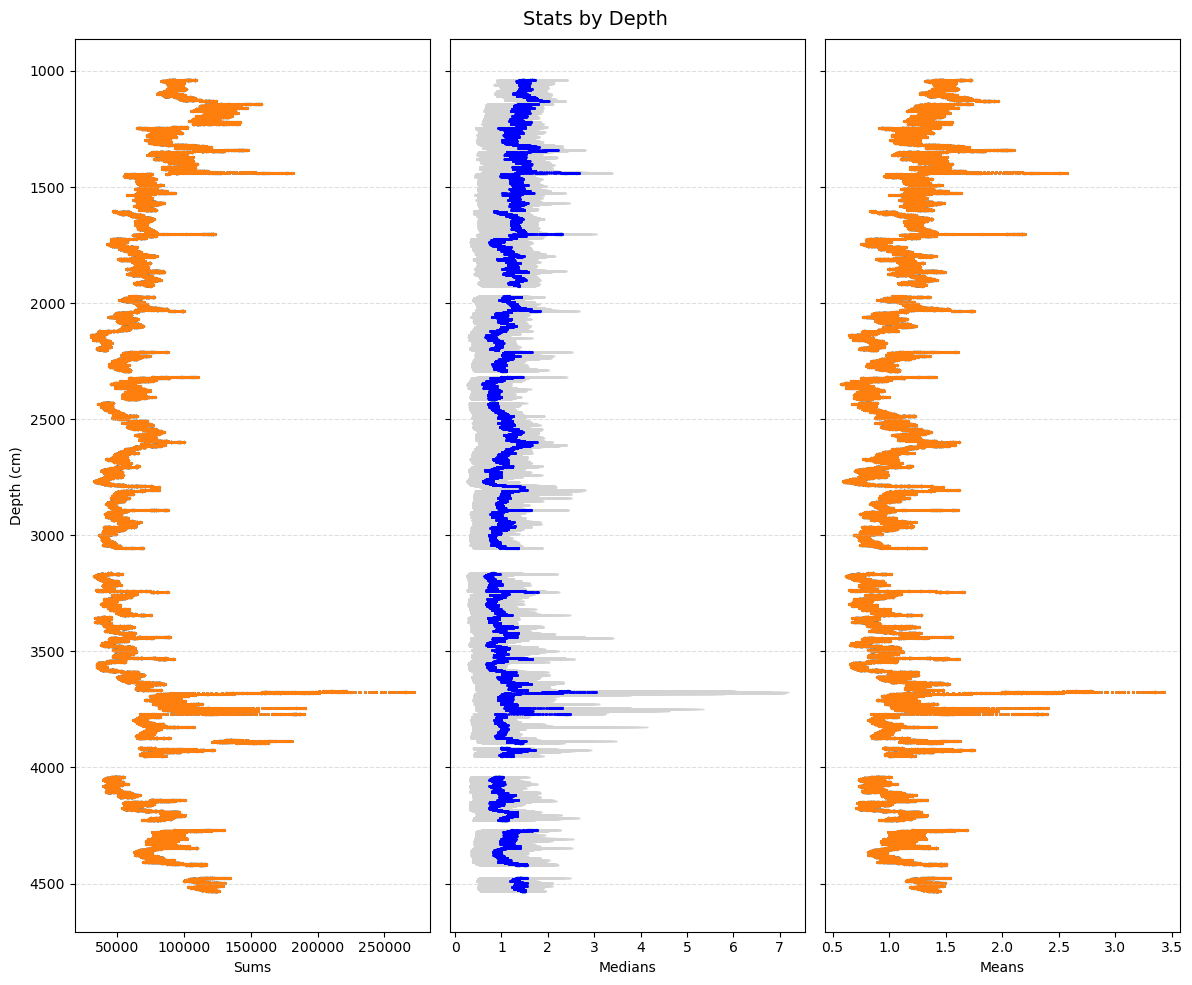

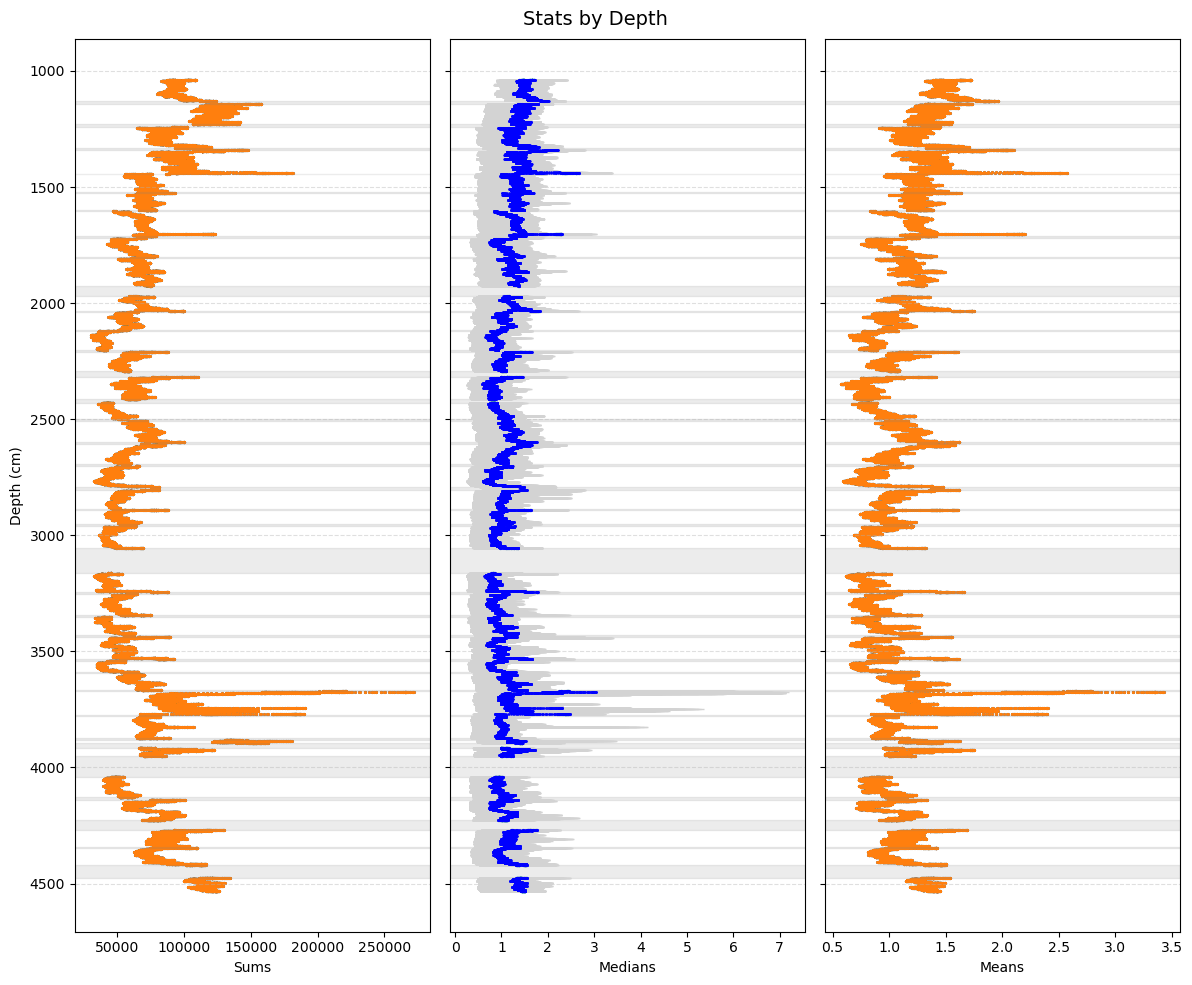

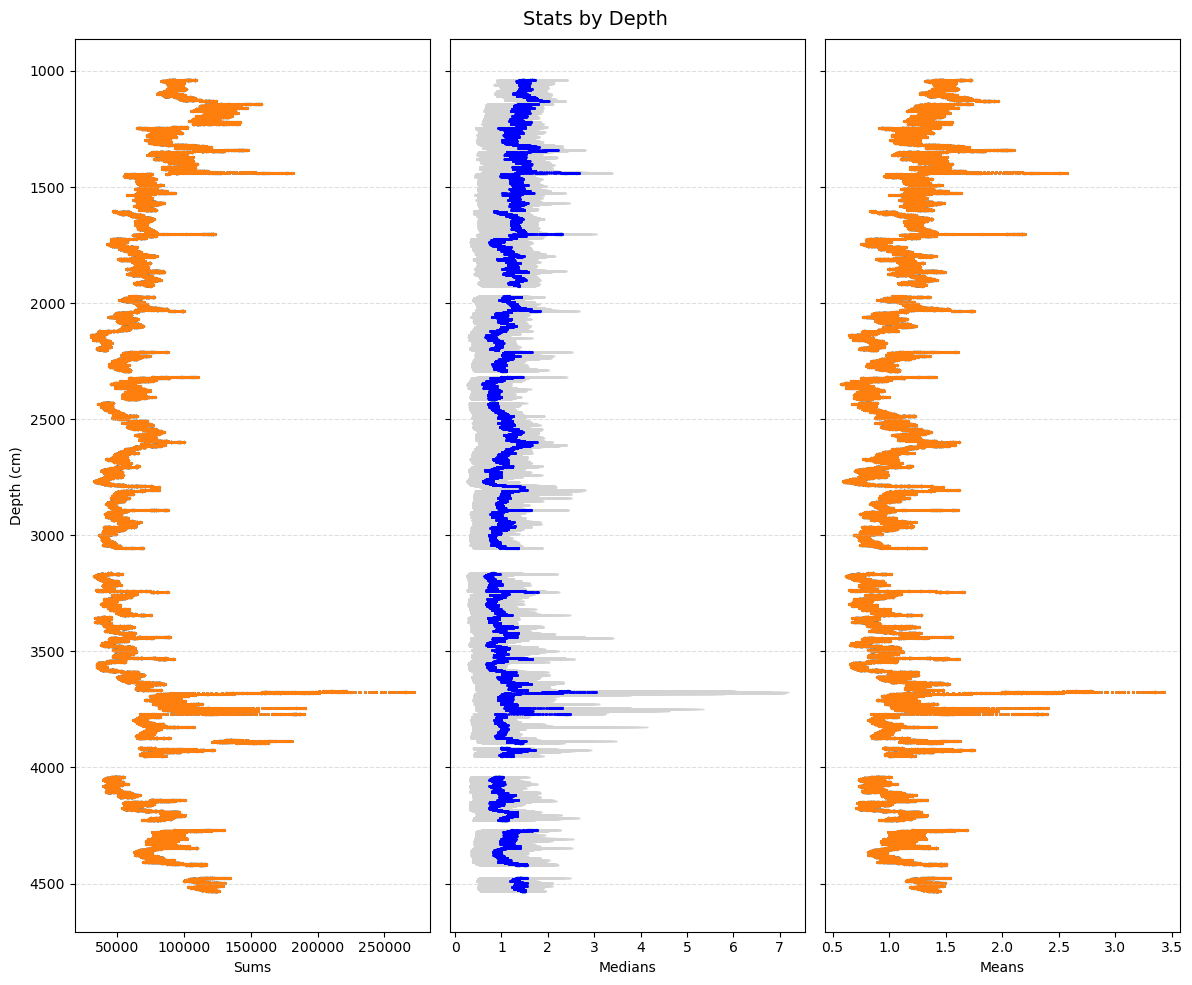

Saved plot files:
stats_by_depth: /data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/2026-03-26_124041/stats_by_depth_shaded.png
pca_scatter: None


In [6]:
results = plot_stats_by_depth(
    combined_df,
    save=True,
    save_path=output_dir,
    show=True,
    invert_depth_axis=True,
    shade_gaps=False,
    gap_threshold=2.0
)

results = plot_stats_by_depth(
    combined_df,
    save=True,
    save_path=output_dir,
    show=True,
    invert_depth_axis=True,
    shade_gaps=True,
    gap_threshold=2.0
)

# With PCA (recommended: standardize=True)
plot_stats_by_depth(
    combined_df,
    save=True,
    save_path="out/plots",
    show=True,
    pca_n_components=2,
    standardize=True
)

print("Saved plot files:")
for name, path in results.items():
    print(f"{name}: {path}")